# T-Lab 2026 RecSys — Задание 1, часть B: обучаемые time-decay агрегаты

Ноутбук самодостаточен: повторяет загрузку, временной сплит, разметку и движок признаков из основного ноутбука
(**идентичные** кандидаты, сплит и метрики), считает ручной бейзлайн **H** как точку отсчёта и исследует вариант **B**:
замену жёстких временных окон экспоненциальными ядрами, форма которых подбирается обучением.

## 0. Настройки
В Kaggle: **Settings → Internet → On** (нужен подтверждённый по телефону аккаунт). GPU для этого ноутбука не нужен.

In [23]:
import os, sys, time, gc, json, math
if os.path.exists("/kaggle"):
    os.system("pip install -q -U 'polars>=1.42' lightgbm huggingface_hub")
import numpy as np
import polars as pl

try:
    import lightgbm as lgb
except ImportError:
    os.system("pip install -q lightgbm")
    import lightgbm as lgb
from sklearn.metrics import roc_auc_score, log_loss

IN_KAGGLE = os.path.exists("/kaggle")
DATA_DIR = "/kaggle/working/yambda" if IN_KAGGLE else os.environ.get("DATA_DIR", "data")
OUT_DIR = "/kaggle/working/out" if IN_KAGGLE else "out"
os.makedirs(OUT_DIR, exist_ok=True)

SAMPLE_USERS = int(os.environ.get("SAMPLE_USERS", 0))  # 0 = все 10k пользователей
TRAIN_DAYS = int(os.environ.get("TRAIN_DAYS", 14))      # сколько дней размеченных примеров в train
SEED = 42
DAY, HOUR, GAP = 86400, 3600, 1800                      # timestamp в секундах (кратен 5)
N_THREADS = os.cpu_count()
print("kaggle:", IN_KAGGLE, "| threads:", N_THREADS, "| sample users:", SAMPLE_USERS or "all")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 2.3.0 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.3.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 2.3.0 which is incompatible.
transformers 5.16.1 requires huggingface-hub<2.0,>=1.5.0, but you have huggingface-hub 2.3.0 which is incompatible.
gradio-client 2.6.1 requires huggingface-hub<2.0,>=0.19.3, but you have huggingface-hub 2.3.0 which is incompatible.
tokenizers 0.23.1 requires huggingface-hub<2.0,>=0.16.4, but you have huggingface-hub 2.3.0 which is incompatible.
cudf-polars-cu12 26.2.1 requires polars<1.36,>=1

kaggle: True | threads: 4 | sample users: all


## 1. Загрузка данных (напрямую с HuggingFace, ~0.5 ГБ)

In [24]:
from huggingface_hub import hf_hub_download

files = ["flat/50m/multi_event.parquet", "artist_item_mapping.parquet", "album_item_mapping.parquet"]
paths = {f: hf_hub_download("yandex/yambda", f, repo_type="dataset", local_dir=DATA_DIR) for f in files}

ev = pl.read_parquet(paths["flat/50m/multi_event.parquet"])
artist = pl.read_parquet(paths["artist_item_mapping.parquet"]).group_by("item_id").agg(pl.col("artist_id").min())
album = pl.read_parquet(paths["album_item_mapping.parquet"]).group_by("item_id").agg(pl.col("album_id").min())

if SAMPLE_USERS:
    uids = ev.select(pl.col("uid").unique()).sample(SAMPLE_USERS, seed=SEED)
    ev = ev.join(uids, on="uid")  # сохраняем ВСЮ историю выбранных пользователей

ev = (
    ev.join(artist, on="item_id", how="left")
    .join(album, on="item_id", how="left")
    .with_columns(pl.col("timestamp").cast(pl.Int64), pl.col("artist_id").fill_null(0), pl.col("album_id").fill_null(0))
    .sort(["uid", "timestamp"])
)
del artist, album; gc.collect()
print(ev.shape)
ev.head()

(47790449, 9)


uid,timestamp,item_id,is_organic,played_ratio_pct,track_length_seconds,event_type,artist_id,album_id
u32,i64,u32,u8,u16,u32,enum,u32,u32
100,39420,8326270,0,100,170,"""listen""",714356,1060653
100,39420,1441281,0,100,105,"""listen""",1043457,547645
100,39625,286361,0,100,185,"""listen""",94924,141751
100,40110,732449,0,100,240,"""listen""",94924,1632076
100,40360,3397170,0,46,130,"""listen""",997338,403561


## 3. Временное разбиение
Глобальный временной сплит, как в протоколе Yambda: test — последний день, valid — предпоследний, train — `TRAIN_DAYS` дней до valid.
Между частями зазор 30 минут. История для признаков — **вся** до момента предсказания (point-in-time).

In [25]:
T_MAX = ev["timestamp"].max()
test_start = T_MAX - DAY
valid_start = test_start - DAY
train_start = valid_start - TRAIN_DAYS * DAY

# флаги событий
ev = ev.with_columns(
    is_listen=(pl.col("event_type") == "listen").cast(pl.Int32),
).with_columns(
    full=((pl.col("event_type") == "listen") & (pl.col("played_ratio_pct") >= 50)).cast(pl.Int32),
    ratio=pl.when(pl.col("event_type") == "listen").then(pl.col("played_ratio_pct").clip(0, 100).cast(pl.Float32) / 100).otherwise(0.0),
    like=(pl.col("event_type") == "like").cast(pl.Int32),
    dislike=(pl.col("event_type") == "dislike").cast(pl.Int32),
    unlike=(pl.col("event_type").is_in(["unlike", "undislike"])).cast(pl.Int32),
    rec=((pl.col("event_type") == "listen") & (pl.col("is_organic") == 0)).cast(pl.Int32),
    rec_full=((pl.col("event_type") == "listen") & (pl.col("is_organic") == 0) & (pl.col("played_ratio_pct") >= 50)).cast(pl.Int32),
)
FLAGS = ["is_listen", "full", "ratio", "like", "dislike", "unlike", "rec", "rec_full"]

# момент предсказания: конец предыдущего прослушивания (строго раньше текущего)
lts = (
    ev.filter(pl.col("is_listen") == 1).select("uid", "timestamp").unique().sort(["uid", "timestamp"])
    .with_columns(ref_ts=pl.col("timestamp").shift(1).over("uid"))
)

labels = (
    ev.filter((pl.col("rec") == 1) & (pl.col("timestamp") >= train_start))
    .with_columns(
        split=pl.when(pl.col("timestamp") >= test_start + GAP).then(pl.lit("test"))
        .when((pl.col("timestamp") >= valid_start + GAP) & (pl.col("timestamp") < test_start)).then(pl.lit("valid"))
        .when(pl.col("timestamp") < valid_start).then(pl.lit("train"))
        .otherwise(None)
    )
    .filter(pl.col("split").is_not_null())
    .join(lts, on=["uid", "timestamp"], how="left")
    .filter(pl.col("ref_ts").is_not_null())
    .select(
        "uid", "item_id", "artist_id", "album_id", "timestamp", "ref_ts", "split",
        "track_length_seconds", y=pl.col("full"),
        day=((pl.col("timestamp") - test_start) // DAY),
    )
    .with_row_index("rid")
)
print(labels.group_by("split").agg(pl.len(), pl.col("y").mean().alias("pos_rate"), pl.col("uid").n_unique().alias("users")).sort("split"))

shape: (3, 4)
┌───────┬─────────┬──────────┬───────┐
│ split ┆ len     ┆ pos_rate ┆ users │
│ ---   ┆ ---     ┆ ---      ┆ ---   │
│ str   ┆ u32     ┆ f64      ┆ u32   │
╞═══════╪═════════╪══════════╪═══════╡
│ test  ┆ 116513  ┆ 0.715259 ┆ 3196  │
│ train ┆ 1443610 ┆ 0.695519 ┆ 7267  │
│ valid ┆ 109257  ┆ 0.713684 ┆ 3142  │
└───────┴─────────┴──────────┴───────┘


## 4. Point-in-time движок признаков
Любой агрегатный признак описывается тройкой **(сущность, окно, статистика)**:
* **сущности:** `user`, `item`, `artist`, `album` (глобальные статистики по всем пользователям) и пары `user×item`, `user×artist`, `user×album` (прямые и косвенные связи);
* **окна:** время до `ref_ts` (1h … all) или последние *k* прослушиваний пользователя;
* **статистики:** число прослушиваний, доля Listen+, средний played_ratio, like-rate, число лайков/дизлайков, конверсия рекомендаций, доля органики, давность.

Реализация без self-join: для каждой сущности строим таблицу **кумулятивных сумм** по времени, а значение в окне `(ref−W, ref]`
получаем двумя `join_asof`: `cum(ref) − cum(ref−W)`. Это O(N log N) и масштабируется на сотни миллионов событий.

In [26]:
ENTITIES = {
    "user": ["uid"],
    "item": ["item_id"],
    "artist": ["artist_id"],
    "album": ["album_id"],
    "user_item": ["uid", "item_id"],
    "user_artist": ["uid", "artist_id"],
    "user_album": ["uid", "album_id"],
}
WINDOWS = {"1h": HOUR, "6h": 6 * HOUR, "1d": DAY, "3d": 3 * DAY, "7d": 7 * DAY, "14d": 14 * DAY, "30d": 30 * DAY, "90d": 90 * DAY, "all": None}
METRICS = ["cnt", "full_rate", "mean_ratio", "like_rate", "n_like", "n_dislike", "rec_full_rate", "org_share"]
COUNT_WINDOWS = [3, 5, 10, 20, 50, 100]
MAX_W = max(v for v in WINDOWS.values() if v)


def cum_table(keys):
    """Кумулятивные суммы флагов по сущности, агрегированные до уровня (сущность, timestamp)."""
    need_hist = ev.filter(pl.col("timestamp") <= T_MAX)  # вся история
    g = (
        need_hist.group_by(keys + ["timestamp"])
        .agg([pl.col(c).sum() for c in FLAGS] + [pl.col("ratio").filter(pl.col("is_listen") == 1).last().alias("last_ratio")])
        .sort(keys + ["timestamp"])
        .with_columns([pl.col(c).cum_sum().over(keys) for c in FLAGS])
        .with_columns(pl.col("last_ratio").forward_fill().over(keys))
    )
    return g.sort("timestamp")


def asof(q, tab, keys, on):
    """Для каждой строки q берём последнюю строку tab с timestamp ≤ q[on] (в рамках той же сущности)."""
    return (
        q.sort(on)
        .join_asof(tab, left_on=on, right_on="timestamp", by=keys, strategy="backward", check_sortedness=False)
        .sort("rid")
    )


def derive(c, prefix, with_recency=False, ref=None):
    """Статистики из (оконных) кумулятивных сумм."""
    cnt = c["is_listen"]
    safe = lambda num, den: pl.when(den > 0).then(num / den).otherwise(None)
    exprs = {
        "cnt": cnt.cast(pl.Float32),
        "full_rate": safe(c["full"], cnt),
        "mean_ratio": safe(c["ratio"], cnt),
        "like_rate": safe(c["like"], cnt),
        "n_like": (c["like"] - c["unlike"]).cast(pl.Float32),
        "n_dislike": c["dislike"].cast(pl.Float32),
        "rec_full_rate": safe(c["rec_full"], c["rec"]),
        "org_share": safe(cnt - c["rec"], cnt),
    }
    return [e.cast(pl.Float32).alias(f"{prefix}__{m}") for m, e in exprs.items()]


def entity_features(name, windows=WINDOWS):
    keys = ENTITIES[name]
    t0 = time.time()
    tab = cum_table(keys)
    q = labels.select(["rid"] + keys + ["ref_ts"])
    base = asof(q, tab, keys, "ref_ts")
    zero = {c: pl.col(c).fill_null(0) for c in FLAGS}
    feats = []
    for wname, w in windows.items():
        if w is None:
            c = {k: pl.col(k).fill_null(0) for k in FLAGS}
            df = base
        else:
            lag = asof(q.with_columns(q_ts=pl.col("ref_ts") - w), tab.select(keys + ["timestamp"] + FLAGS), keys, "q_ts")
            df = base.select(["rid"] + FLAGS).with_columns(
                [(pl.col(k).fill_null(0) - lag[k].fill_null(0)).alias(k) for k in FLAGS]
            )
            c = {k: pl.col(k) for k in FLAGS}
        feats.append(df.select(derive(c, f"{name}__{wname}")))
    extra = base.select(
        ((pl.col("ref_ts") - pl.col("timestamp")) / DAY).cast(pl.Float32).alias(f"{name}__all__recency_days"),
        pl.col("last_ratio").cast(pl.Float32).alias(f"{name}__all__last_ratio"),
    )
    out = pl.concat(feats + [extra], how="horizontal")
    print(f"{name:12s} {out.width:4d} features  {time.time() - t0:6.1f}s")
    del tab, base; gc.collect()
    return out


def count_window_features():
    """Окна в терминах последних k прослушиваний пользователя (а не времени)."""
    t0 = time.time()
    ul = (
        ev.filter(pl.col("is_listen") == 1).select("uid", "timestamp", "full", "ratio", "rec")
        .sort(["uid", "timestamp"])
        .with_columns(idx=pl.int_range(1, pl.len() + 1).over("uid"),
                      c_full=pl.col("full").cum_sum().over("uid"),
                      c_ratio=pl.col("ratio").cum_sum().over("uid"),
                      c_rec=pl.col("rec").cum_sum().over("uid"))
    )
    by_ts = ul.group_by(["uid", "timestamp"]).agg(pl.all().exclude(["full", "ratio", "rec"]).last()).sort("timestamp")
    q = labels.select("rid", "uid", "ref_ts")
    b = asof(q, by_ts, ["uid"], "ref_ts")
    idx_tab = ul.select("uid", "idx", "c_full", "c_ratio", "c_rec")
    cols = []
    for k in COUNT_WINDOWS:
        lag = b.select("rid", "uid", (pl.col("idx") - k).alias("idx")).join(idx_tab, on=["uid", "idx"], how="left").sort("rid")
        n = (b["idx"] - (b["idx"] - k).clip(0, None)).cast(pl.Float32)
        cols += [
            ((b["c_full"] - lag["c_full"].fill_null(0)) / n).alias(f"user__last{k}__full_rate"),
            ((b["c_ratio"] - lag["c_ratio"].fill_null(0)) / n).alias(f"user__last{k}__mean_ratio"),
            ((b["c_rec"] - lag["c_rec"].fill_null(0)) / n).alias(f"user__last{k}__rec_share"),
        ]
    out = pl.DataFrame([c.cast(pl.Float32) for c in cols])
    print(f"{'count_win':12s} {out.width:4d} features  {time.time() - t0:6.1f}s")
    return out

## 4.1 Ручные признаки H (точка отсчёта)

In [27]:
H_WINDOWS = {
    "user": ["1d", "7d", "30d", "all"], "item": ["7d", "all"], "artist": ["30d", "all"], "album": ["all"],
    "user_item": ["all"], "user_artist": ["30d", "all"], "user_album": ["all"],
}
t_feat = time.time()
blocks = [entity_features(n, {w: WINDOWS[w] for w in ws}) for n, ws in H_WINDOWS.items()] + [count_window_features()]
context = labels.select(
    pl.col("track_length_seconds").cast(pl.Float32).alias("ctx__track_length"),
    ((pl.col("ref_ts") % DAY) / HOUR).cast(pl.Float32).alias("ctx__hour_phase"),
)
X_all = pl.concat(blocks + [context], how="horizontal")
FEAT_TIME = time.time() - t_feat
print(f"H-движок: {X_all.width} признаков, {FEAT_TIME:.0f}s")

user           34 features    31.1s
item           18 features    40.3s
artist         18 features    34.9s
album          10 features    34.2s
user_item      10 features    94.6s
user_artist    18 features    70.8s
user_album     10 features    83.9s
count_win      18 features    32.0s
H-движок: 138 признаков, 423s


## 5. Обучение и метрики

In [28]:
def rank_metrics(meta, pred, k=10):
    """NDCG@k и Recall@k внутри (пользователь, день); группы только со смешанными таргетами."""
    d = meta.select("uid", "day", "y").with_columns(p=pl.Series(pred))
    d = d.filter((pl.col("y").sum().over(["uid", "day"]) > 0) & (pl.col("y").sum().over(["uid", "day"]) < pl.len().over(["uid", "day"])))
    d = d.with_columns(
        r=pl.col("p").rank("ordinal", descending=True).over(["uid", "day"]),
        ir=pl.col("y").rank("ordinal", descending=True).over(["uid", "day"]),
    )
    g = d.group_by(["uid", "day"]).agg(
        dcg=(pl.col("y") / (pl.col("r") + 1).log(2)).filter(pl.col("r") <= k).sum(),
        idcg=(pl.col("y").sort(descending=True).head(k) / (pl.int_range(2, pl.len().clip(None, k) + 2)).log(2)).sum(),
        hit=pl.col("y").filter(pl.col("r") <= k).sum(),
        npos=pl.col("y").sum(),
    )
    return {"ndcg@10": (g["dcg"] / g["idcg"]).mean(), "recall@10": (g["hit"] / g["npos"].clip(None, k)).mean(), "groups": g.height}


def evaluate(name, y, p, meta, extra=None):
    res = {"model": name, "auc": roc_auc_score(y, p), "logloss": log_loss(y, np.clip(p, 1e-6, 1 - 1e-6))}
    res.update(rank_metrics(meta, p))
    if extra: res.update(extra)
    return res


masks = {s: (labels["split"] == s).to_numpy() for s in ["train", "valid", "test"]}
Y = labels["y"].to_numpy()
META = {s: labels.filter(pl.col("split") == s) for s in masks}

LGB_PARAMS = dict(objective="binary", learning_rate=0.05, num_leaves=127, min_data_in_leaf=200, feature_fraction=0.8,
                  bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, metric="auc", verbose=-1, num_threads=N_THREADS, seed=SEED)


def fit_lgb(cols, params=LGB_PARAMS, rounds=3000, train_rows=None, es=100):
    Xtr = X_all.select(cols).filter(pl.Series(masks["train"])).to_numpy()
    ytr = Y[masks["train"]]
    if train_rows and len(ytr) > train_rows:
        idx = np.random.default_rng(SEED).choice(len(ytr), train_rows, replace=False)
        Xtr, ytr = Xtr[idx], ytr[idx]
    Xva = X_all.select(cols).filter(pl.Series(masks["valid"])).to_numpy()
    dtr = lgb.Dataset(Xtr, ytr, feature_name=cols, free_raw_data=True)
    dva = lgb.Dataset(Xva, Y[masks["valid"]], reference=dtr)
    t0 = time.time()
    m = lgb.train(params, dtr, rounds, valid_sets=[dva], callbacks=[lgb.early_stopping(es, verbose=False)])
    return m, time.time() - t0


def run(name, cols, results):
    m, fit_time = fit_lgb(cols)
    out = {}
    for s in ["valid", "test"]:
        p = m.predict(X_all.select(cols).filter(pl.Series(masks[s])).to_numpy(), num_iteration=m.best_iteration)
        out[s] = evaluate(name, Y[masks[s]], p, META[s], {"n_feat": len(cols), "fit_s": round(fit_time, 1), "iters": m.best_iteration})
    results.append(out)
    print(name, "| valid:", {k: round(v, 4) for k, v in out["valid"].items() if isinstance(v, float)},
          "| test:", {k: round(v, 4) for k, v in out["test"].items() if isinstance(v, float)})
    return m


results = []

### 5.1 H — ручные признаки
Типичный выбор инженера: стандартные окна (1d / 7d / 30d / all), базовые статистики по каждой сущности, последние 10 прослушиваний, контекст.

In [29]:
def pick(entity, windows, metrics):
    return [f"{entity}__{w}__{m}" for w in windows for m in metrics]

H_COLS = (
    pick("user", ["1d", "7d", "30d", "all"], ["cnt", "full_rate", "like_rate", "rec_full_rate"])
    + pick("item", ["7d", "all"], ["cnt", "full_rate", "mean_ratio", "like_rate"])
    + pick("artist", ["30d", "all"], ["cnt", "full_rate"])
    + pick("album", ["all"], ["cnt", "full_rate"])
    + pick("user_item", ["all"], ["cnt", "full_rate", "n_like", "n_dislike", "recency_days", "last_ratio"])
    + pick("user_artist", ["30d", "all"], ["cnt", "full_rate", "n_like"]) + ["user_artist__all__recency_days"]
    + pick("user_album", ["all"], ["cnt", "full_rate"])
    + ["user__last10__full_rate", "user__last10__mean_ratio", "ctx__track_length", "ctx__hour_phase"]
)
assert all(c in X_all.columns for c in H_COLS)
print("H:", len(H_COLS), "признаков")
m_H = run("H (manual)", H_COLS, results)

H: 49 признаков
H (manual) | valid: {'auc': np.float64(0.8941), 'logloss': 0.3606, 'ndcg@10': 0.7569, 'recall@10': 0.8249, 'fit_s': 65.1} | test: {'auc': np.float64(0.8999), 'logloss': 0.3508, 'ndcg@10': 0.745, 'recall@10': 0.8117, 'fit_s': 65.1}


## 6. Вариант B: обучаемые агрегаты с экспоненциальным затуханием

**Идея.** Ручной признак «число прослушиваний артиста за 7 дней» — это свёртка истории с *прямоугольным* ядром фиксированной ширины.
Заменим жёсткие окна на **экспоненциальные ядра** и будем подбирать их форму **градиентом**, а не перебором.

Для каждой связи *r* (user, item, artist, album, user×item, user×artist, user×album), сигнала *e* (listen, Listen+, like, dislike,
rec, rec Listen+) и масштаба τ_k из сетки считаем

$$D_{r,e,k}(t) = \sum_{j \in r,\ t_j \le t} x_{j,e}\, e^{-(t-t_j)/\tau_k}$$

* **Масштабируемость.** Счётчик обновляется за O(1) на событие: `S ← S·exp(−Δt/τ) + x`. Его можно держать в онлайн-хранилище признаков и не хранить историю вообще; это ответ на вопрос задания о масштабе (миллиарды событий).
* **Обучаемость.** Модель B-net для каждой связи учит *H* «мягких окон» — выпуклые смеси ядер `softmax(α_{r,h})·D_{r,·,k}`. Выученный эффективный горизонт `τ_eff = exp(Σ w_k log τ_k)` интерпретируем: он отвечает на вопрос «почему 7 дней?» обучением.

**Эксперименты (одинаковые сплит, кандидаты и метрики, что и в части H/A):**
1. `B-grid → LightGBM` — фиксированная сетка затухающих счётчиков как признаки бустинга (без ручного выбора окон);
2. `B-net` — end-to-end нейросеть с обучаемыми окнами;
3. `B-net features → LightGBM` — выученные мягкие окна как признаки бустинга (дистилляция);
4. `H + B-grid` — дают ли затухающие счётчики прирост поверх ручных признаков.

In [30]:
try:
    import numba
except ImportError:
    os.system("pip install -q numba"); import numba
from numba import njit

TAUS = np.array([600, HOUR, 6 * HOUR, DAY, 3 * DAY, 7 * DAY, 30 * DAY, 120 * DAY], dtype=np.float64)
TAU_NAMES = ["10m", "1h", "6h", "1d", "3d", "7d", "30d", "120d"]
SIGNALS = ["is_listen", "full", "like_net", "dislike", "rec", "rec_full"]
REL = list(ENTITIES)
ev = ev.with_columns(like_net=(pl.col("like") - pl.col("unlike")))


@njit(cache=True)
def decay_scan(keys, ts, is_q, X, qidx, taus, out):
    """Один проход по потоку (сущность, время): события обновляют состояние, запросы его читают.
    Запрос на том же timestamp идёт после событий, то есть учитываются события с t_j ≤ ref_ts."""
    E, K = X.shape[1], taus.shape[0]
    S = np.zeros((E, K))
    cur = -1
    last_t = 0.0
    for i in range(keys.shape[0]):
        if keys[i] != cur:
            cur = keys[i]
            S[:, :] = 0.0
            last_t = ts[i]
        dt = ts[i] - last_t
        if is_q[i]:
            for k in range(K):
                f = np.exp(-dt / taus[k])
                for e in range(E):
                    out[qidx[i], e, k] = S[e, k] * f
        else:
            for k in range(K):
                f = np.exp(-dt / taus[k])
                for e in range(E):
                    S[e, k] = S[e, k] * f + X[i, e]
            last_t = ts[i]


def key_expr(keys):
    return pl.col(keys[0]).cast(pl.Int64) if len(keys) == 1 else (pl.col(keys[0]).cast(pl.Int64) * (1 << 32) + pl.col(keys[1]).cast(pl.Int64))


def decay_features(name):
    t0 = time.time()
    keys = ENTITIES[name]
    e = (
        ev.group_by(keys + ["timestamp"]).agg([pl.col(c).sum().cast(pl.Float32) for c in SIGNALS])
        .select(key=key_expr(keys), ts=pl.col("timestamp"), q=pl.lit(0, pl.Int8), qidx=pl.lit(-1, pl.Int64), *SIGNALS)
    )
    q = labels.select(key=key_expr(keys), ts=pl.col("ref_ts"), q=pl.lit(1, pl.Int8), qidx=pl.col("rid").cast(pl.Int64),
                      **{c: pl.lit(0.0, pl.Float32) for c in SIGNALS})
    st = pl.concat([e, q.select(e.columns)]).sort(["key", "ts", "q"])
    out = np.zeros((labels.height, len(SIGNALS), len(TAUS)), dtype=np.float32)
    decay_scan(st["key"].to_numpy(), st["ts"].to_numpy().astype(np.float64), st["q"].to_numpy().astype(np.bool_),
               st.select(SIGNALS).to_numpy().astype(np.float64), st["qidx"].to_numpy(), TAUS, out)
    print(f"{name:12s} decay scan over {st.height:>10,d} rows  {time.time() - t0:6.1f}s")
    del e, q, st; gc.collect()
    return out


t_dec = time.time()
D = np.stack([decay_features(r) for r in REL], axis=1)  # [N, R, E, K]
DECAY_TIME = time.time() - t_dec
print("D shape:", D.shape, f"| {DECAY_TIME:.0f}s")
np.save(f"{OUT_DIR}/decay_D.npy", D)

user         decay scan over 39,954,318 rows    34.5s
item         decay scan over 48,727,946 rows    35.6s
artist       decay scan over 47,304,297 rows    36.3s
album        decay scan over 48,214,409 rows    34.7s
user_item    decay scan over 48,750,751 rows    32.8s
user_artist  decay scan over 47,465,596 rows    31.5s
user_album   decay scan over 48,257,269 rows    32.2s
D shape: (1669380, 7, 6, 8) | 240s


### 6.1 B-grid → LightGBM
Сырые затухающие счётчики плюс сглаженные доли (Listen+-rate, конверсия рекомендаций) для каждой пары (связь, τ). Окна никто не выбирал.

In [31]:
def decay_frame(D):
    cols = {}
    for ri, r in enumerate(REL):
        for ki, tn in enumerate(TAU_NAMES):
            d = D[:, ri, :, ki]
            for ei, s in enumerate(SIGNALS):
                cols[f"B_{r}__{tn}__{s}"] = d[:, ei]
            cols[f"B_{r}__{tn}__full_rate"] = (d[:, 1] + 0.7) / (d[:, 0] + 1.0)
            cols[f"B_{r}__{tn}__rec_full_rate"] = (d[:, 5] + 0.7) / (d[:, 4] + 1.0)
            cols[f"B_{r}__{tn}__like_rate"] = d[:, 2] / (d[:, 0] + 1.0)
    return pl.DataFrame(cols)

XB = decay_frame(D)
CTX_COLS = ["ctx__track_length", "ctx__hour_phase"]
X_all = pl.concat([X_all, XB], how="horizontal")
BGRID_COLS = XB.columns + CTX_COLS
print("B-grid:", len(BGRID_COLS), "признаков")
m_Bgrid = run("B-grid -> LightGBM", BGRID_COLS, results)

B-grid: 506 признаков
B-grid -> LightGBM | valid: {'auc': np.float64(0.9027), 'logloss': 0.3476, 'ndcg@10': 0.7645, 'recall@10': 0.8361, 'fit_s': 548.4} | test: {'auc': np.float64(0.907), 'logloss': 0.3388, 'ndcg@10': 0.7551, 'recall@10': 0.825, 'fit_s': 548.4}


In [32]:
m_HB = run("H + B-grid", list(dict.fromkeys(H_COLS + BGRID_COLS)), results)

H + B-grid | valid: {'auc': np.float64(0.9041), 'logloss': 0.3453, 'ndcg@10': 0.77, 'recall@10': 0.8403, 'fit_s': 507.5} | test: {'auc': np.float64(0.9084), 'logloss': 0.3366, 'ndcg@10': 0.7606, 'recall@10': 0.8281, 'fit_s': 507.5}


### 6.2 B-net: end-to-end обучаемые окна
Для каждой связи *r* — `H_HEADS` мягких окон `w_{r,h} = softmax(α_{r,h}) ∈ Δ^K`. Для каждого окна считаются смешанные счётчики
`c_{r,h,e} = Σ_k w_{r,h,k} D_{r,e,k}`, из них — `log1p(count)`, сглаженные доли Listen+ / like / dislike / конверсии рекомендаций.
Поверх — MLP. Головы инициализированы на разных масштабах, чтобы окна были разнесены по оси времени.

In [33]:
import torch, torch.nn as nn
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
H_HEADS = 4


class DecayNet(nn.Module):
    def __init__(self, R, E, K, n_ctx, heads=H_HEADS, hidden=256):
        super().__init__()
        init = torch.full((R, heads, K), -2.0)
        for h in range(heads):  # голова h стартует с пика на своём масштабе
            init[:, h, int(round(h * (K - 1) / max(heads - 1, 1)))] = 2.0
        self.alpha = nn.Parameter(init)
        n_in = R * heads * 6 + n_ctx
        self.bn = nn.BatchNorm1d(n_in)
        self.mlp = nn.Sequential(nn.Linear(n_in, hidden), nn.ReLU(), nn.Dropout(0.1),
                                 nn.Linear(hidden, hidden // 2), nn.ReLU(), nn.Linear(hidden // 2, 1))

    def windows(self):
        return torch.softmax(self.alpha, -1)  # [R, H, K]

    def soft_features(self, D):
        c = torch.einsum("nrek,rhk->nrhe", D, self.windows())
        lis, full, like, dis, rec, recf = [c[..., i] for i in range(6)]
        f = torch.stack([torch.log1p(lis), (full + 0.7) / (lis + 1), like / (lis + 1), dis / (lis + 1),
                         (recf + 0.7) / (rec + 1), torch.log1p(rec)], -1)
        return f.flatten(1)

    def forward(self, D, ctx):
        return self.mlp(self.bn(torch.cat([self.soft_features(D), ctx], 1))).squeeze(1)


ctx_np = np.stack([np.log1p(labels["track_length_seconds"].fill_null(0).to_numpy().astype(np.float32)),
                   np.sin(2 * np.pi * X_all["ctx__hour_phase"].to_numpy() / 24),
                   np.cos(2 * np.pi * X_all["ctx__hour_phase"].to_numpy() / 24)], 1).astype(np.float32)
T = {s: (torch.from_numpy(D[masks[s]]), torch.from_numpy(ctx_np[masks[s]]), torch.from_numpy(Y[masks[s]].astype(np.float32))) for s in masks}


def predict(net, s, bs=65536):
    net.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(T[s][2]), bs):
            out.append(torch.sigmoid(net(T[s][0][i:i + bs].to(DEVICE), T[s][1][i:i + bs].to(DEVICE))).cpu())
    return torch.cat(out).numpy()


net = DecayNet(len(REL), len(SIGNALS), len(TAUS), ctx_np.shape[1]).to(DEVICE)
opt = torch.optim.AdamW([{"params": [net.alpha], "lr": 2e-2}, {"params": [p for n, p in net.named_parameters() if n != "alpha"], "lr": 2e-3}], weight_decay=1e-5)
lossf = nn.BCEWithLogitsLoss()
best_auc, best_state, patience, BS = 0, None, 0, 4096
t0 = time.time()
for epoch in range(30):
    net.train()
    perm = torch.randperm(len(T["train"][2]))
    for i in range(0, len(perm), BS):
        b = perm[i:i + BS]
        loss = lossf(net(T["train"][0][b].to(DEVICE), T["train"][1][b].to(DEVICE)), T["train"][2][b].to(DEVICE))
        opt.zero_grad(); loss.backward(); opt.step()
    auc = roc_auc_score(Y[masks["valid"]], predict(net, "valid"))
    print(f"epoch {epoch:2d} loss {loss.item():.4f} valid auc {auc:.5f}")
    if auc > best_auc + 1e-4:
        best_auc, best_state, patience = auc, {k: v.detach().clone() for k, v in net.state_dict().items()}, 0
    else:
        patience += 1
        if patience >= 3: break
BNET_TIME = time.time() - t0
net.load_state_dict(best_state)
out = {s: evaluate("B-net (learned windows)", Y[masks[s]], predict(net, s), META[s],
                   {"n_feat": len(REL) * H_HEADS * 6 + ctx_np.shape[1], "fit_s": round(BNET_TIME, 1)}) for s in ["valid", "test"]}
results.append(out)
print(out["test"])

epoch  0 loss 0.3410 valid auc 0.89904
epoch  1 loss 0.3559 valid auc 0.90007
epoch  2 loss 0.3575 valid auc 0.90068
epoch  3 loss 0.3508 valid auc 0.90091
epoch  4 loss 0.3670 valid auc 0.90143
epoch  5 loss 0.3576 valid auc 0.90132
epoch  6 loss 0.3575 valid auc 0.90162
epoch  7 loss 0.3570 valid auc 0.90196
epoch  8 loss 0.3733 valid auc 0.90140
epoch  9 loss 0.3375 valid auc 0.90162
epoch 10 loss 0.3603 valid auc 0.90204
{'model': 'B-net (learned windows)', 'auc': np.float64(0.9063318615114284), 'logloss': 0.34058727288001256, 'ndcg@10': 0.756433520214497, 'recall@10': 0.8258178495278709, 'groups': 2345, 'n_feat': 171, 'fit_s': 26.8}


### 6.3 Выученные окна: какие горизонты важны для каждой связи

shape: (7, 5)
┌─────────────┬───────┬───────┬───────┬────────┐
│ relation    ┆ head0 ┆ head1 ┆ head2 ┆ head3  │
│ ---         ┆ ---   ┆ ---   ┆ ---   ┆ ---    │
│ str         ┆ str   ┆ str   ┆ str   ┆ str    │
╞═════════════╪═══════╪═══════╪═══════╪════════╡
│ user        ┆ 10m   ┆ 1.0h  ┆ 8.8h  ┆ 3.6d   │
│ item        ┆ 11m   ┆ 5.9h  ┆ 4.1d  ┆ 61.5d  │
│ artist      ┆ 12m   ┆ 3.1h  ┆ 4.2d  ┆ 3.4d   │
│ album       ┆ 13m   ┆ 5.2h  ┆ 5.4d  ┆ 107.3d │
│ user_item   ┆ 13m   ┆ 7.0h  ┆ 2.1h  ┆ 23.2d  │
│ user_artist ┆ 12m   ┆ 3.5h  ┆ 6.6d  ┆ 117.2d │
│ user_album  ┆ 11m   ┆ 6.2h  ┆ 3.5d  ┆ 117.2d │
└─────────────┴───────┴───────┴───────┴────────┘


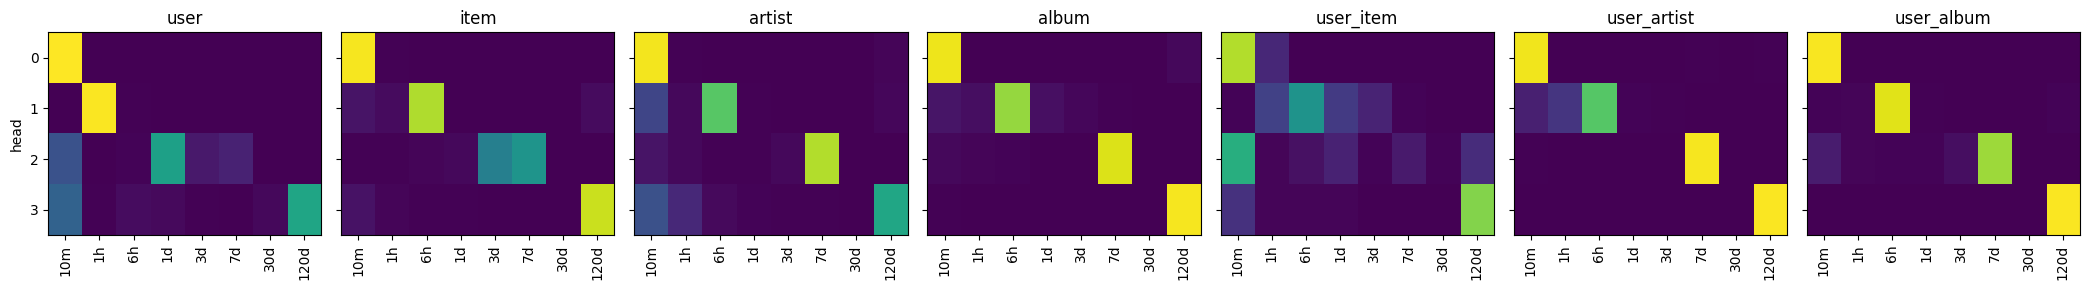

In [34]:
W = net.windows().detach().cpu().numpy()  # [R, H, K]
tau_eff = np.exp((W * np.log(TAUS)[None, None, :]).sum(-1))  # [R, H]
fmt = lambda s: f"{s / 60:.0f}m" if s < HOUR else (f"{s / HOUR:.1f}h" if s < DAY else f"{s / DAY:.1f}d")
win_tab = pl.DataFrame({"relation": REL, **{f"head{h}": [fmt(tau_eff[r, h]) for r in range(len(REL))] for h in range(H_HEADS)}})
print(win_tab)
win_tab.write_csv(f"{OUT_DIR}/learned_windows.csv")

try:
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, len(REL), figsize=(3 * len(REL), 3), sharey=True)
    for r, ax in enumerate(axes):
        ax.imshow(W[r], aspect="auto", cmap="viridis", vmin=0, vmax=1)
        ax.set_title(REL[r]); ax.set_xticks(range(len(TAUS))); ax.set_xticklabels(TAU_NAMES, rotation=90)
        ax.set_yticks(range(H_HEADS))
    axes[0].set_ylabel("head")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/learned_windows.png", dpi=120); plt.show()
except Exception as ex:
    print("plot skipped:", ex)

### 6.4 Дистилляция: выученные мягкие окна → LightGBM
Признаки `soft_features` из обученной B-net (только преобразование D выученными окнами, без MLP) отдаём бустингу.

In [35]:
with torch.no_grad():
    SF = np.concatenate([net.soft_features(torch.from_numpy(D[i:i + 65536]).to(DEVICE)).cpu().numpy() for i in range(0, len(D), 65536)])
SF_COLS = [f"BL_{r}__h{h}__{f}" for r in REL for h in range(H_HEADS) for f in ["logcnt", "full_rate", "like_rate", "dislike_rate", "rec_full_rate", "logrec"]]
X_all = pl.concat([X_all, pl.DataFrame(SF, schema=SF_COLS)], how="horizontal")
m_BL = run("B-net features -> LightGBM", SF_COLS + CTX_COLS, results)
m_HBL = run("H + B-net features", list(dict.fromkeys(H_COLS + SF_COLS + CTX_COLS)), results)

B-net features -> LightGBM | valid: {'auc': np.float64(0.9024), 'logloss': 0.348, 'ndcg@10': 0.762, 'recall@10': 0.8336, 'fit_s': 195.3} | test: {'auc': np.float64(0.9068), 'logloss': 0.3392, 'ndcg@10': 0.7543, 'recall@10': 0.8242, 'fit_s': 195.3}
H + B-net features | valid: {'auc': np.float64(0.9043), 'logloss': 0.3449, 'ndcg@10': 0.7701, 'recall@10': 0.8384, 'fit_s': 245.1} | test: {'auc': np.float64(0.9085), 'logloss': 0.3365, 'ndcg@10': 0.7609, 'recall@10': 0.828, 'fit_s': 245.1}


## 7. Итоговая таблица (test) и стоимость

In [36]:
rows = [{"split": s, **r[s]} for r in results for s in ["valid", "test"]]
res_df = pl.DataFrame(rows).with_columns(pl.col(pl.Float64).round(4))
print(res_df.filter(pl.col("split") == "test"))
res_df.write_csv(f"{OUT_DIR}/results_task1_B.csv")
print(f"decay scan: {DECAY_TIME:.0f}s for {D.shape[1] * D.shape[2] * D.shape[3]} counters | B-net training: {BNET_TIME / 60:.1f} min on {DEVICE}")

shape: (6, 10)
┌───────┬────────────────────────────┬────────┬─────────┬───┬────────┬────────┬───────┬───────┐
│ split ┆ model                      ┆ auc    ┆ logloss ┆ … ┆ groups ┆ n_feat ┆ fit_s ┆ iters │
│ ---   ┆ ---                        ┆ ---    ┆ ---     ┆   ┆ ---    ┆ ---    ┆ ---   ┆ ---   │
│ str   ┆ str                        ┆ f64    ┆ f64     ┆   ┆ i64    ┆ i64    ┆ f64   ┆ i64   │
╞═══════╪════════════════════════════╪════════╪═════════╪═══╪════════╪════════╪═══════╪═══════╡
│ test  ┆ H (manual)                 ┆ 0.8999 ┆ 0.3508  ┆ … ┆ 2345   ┆ 49     ┆ 65.1  ┆ 272   │
│ test  ┆ B-grid -> LightGBM         ┆ 0.907  ┆ 0.3388  ┆ … ┆ 2345   ┆ 506    ┆ 548.4 ┆ 457   │
│ test  ┆ H + B-grid                 ┆ 0.9084 ┆ 0.3366  ┆ … ┆ 2345   ┆ 553    ┆ 507.5 ┆ 310   │
│ test  ┆ B-net (learned windows)    ┆ 0.9063 ┆ 0.3406  ┆ … ┆ 2345   ┆ 171    ┆ 26.8  ┆ null  │
│ test  ┆ B-net features -> LightGBM ┆ 0.9068 ┆ 0.3392  ┆ … ┆ 2345   ┆ 170    ┆ 195.3 ┆ 401   │
│ test  ┆ H + B-net featu